# Experiment 4: Statistical Hypothesis Testing Using Python

**Aim:** To perform statistical hypothesis testing on the Titanic dataset using Python and interpret the results using p-values.

**Mapped CO(s):** CO2

## 1. Import Required Libraries

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
ALPHA = 0.05

## 2. Load the Titanic Dataset

In [11]:
df = sns.load_dataset("titanic")

print("Dataset loaded successfully")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully
Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 3. Select Variables and Handle Missing Values

In [12]:
data = df[["survived", "age"]].dropna()

print("Rows after removing missing Age values:", len(data))
print("Missing values remaining:", data.isna().sum().sum())
data.head()

Rows after removing missing Age values: 714
Missing values remaining: 0


,survived,age
0,0,22.0
1,1,38.0
2,1,26.0
3,1,35.0
4,0,35.0


## 4. Formulate Hypotheses

**Question:** Does the average age of passengers differ significantly based on survival status?

- **Null Hypothesis (H0):** There is no significant difference in mean age between survived and non-survived passengers.
  - H0: mu_survived = mu_not_survived
- **Alternative Hypothesis (H1):** There is a significant difference in mean age between survived and non-survived passengers.
  - H1: mu_survived != mu_not_survived
- **Significance level:** alpha = 0.05
- **Test:** Independent (two-sample) t-test

## 5. Separate Survived and Not Survived Groups

In [13]:
age_survived = data.loc[data["survived"] == 1, "age"]
age_not_survived = data.loc[data["survived"] == 0, "age"]

summary = pd.DataFrame({
    "Group": ["Survived", "Not Survived"],
    "Count": [len(age_survived), len(age_not_survived)],
    "Mean Age": [age_survived.mean(), age_not_survived.mean()],
    "Std Dev": [age_survived.std(), age_not_survived.std()]
})

print("Group summary:")
summary.round(3)

Group summary:


,Group,Count,Mean Age,Std Dev
0,Survived,290,28.344,14.951
1,Not Survived,424,30.626,14.172


/var/folders/9l/rs7bfxps4jd0jsfdd_hrzvjr0000gn/T/ipykernel_2284/3312869486.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x="survived", y="age", palette="Set2")


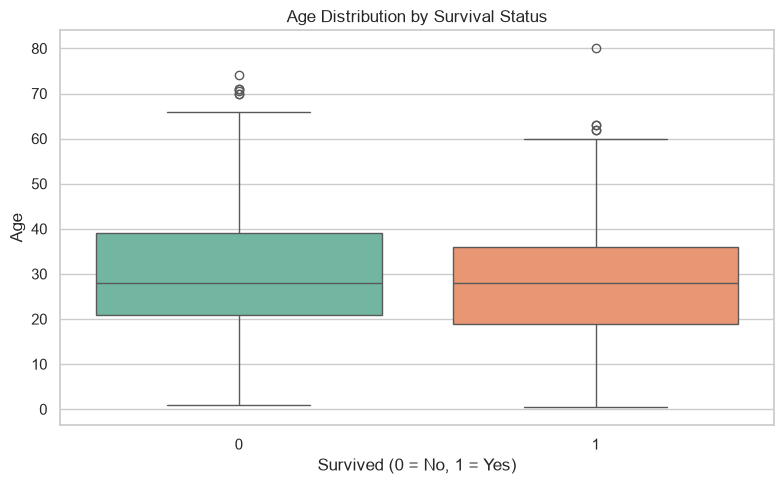

In [14]:
sns.boxplot(data=data, x="survived", y="age", palette="Set2")
plt.title("Age Distribution by Survival Status")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Age")
plt.tight_layout()
plt.show()

## 6. Independent Sample t-test (Age)

In [15]:
t_stat, p_value = stats.ttest_ind(age_survived, age_not_survived, equal_var=False)

print("Independent Sample t-test (Age ~ Survived)")
print(f"t-statistic = {t_stat:.4f}")
print(f"p-value     = {p_value:.6f}")
print(f"alpha       = {ALPHA}")

if p_value < ALPHA:
    print("\nDecision: Reject H0")
    print("Conclusion: There is a statistically significant difference in mean age between survived and non-survived passengers.")
else:
    print("\nDecision: Fail to reject H0")
    print("Conclusion: There is no statistically significant difference in mean age between survived and non-survived passengers.")

Independent Sample t-test (Age ~ Survived)
t-statistic = -2.0460
p-value     = 0.041190
alpha       = 0.05

Decision: Reject H0
Conclusion: There is a statistically significant difference in mean age between survived and non-survived passengers.


---
## Exercises / Assignments

### Exercise 1: t-test using Fare instead of Age

In [16]:
fare_data = df[["survived", "fare"]].dropna()
fare_survived = fare_data.loc[fare_data["survived"] == 1, "fare"]
fare_not_survived = fare_data.loc[fare_data["survived"] == 0, "fare"]

print("Mean Fare - Survived:", round(fare_survived.mean(), 2))
print("Mean Fare - Not Survived:", round(fare_not_survived.mean(), 2))

t_fare, p_fare = stats.ttest_ind(fare_survived, fare_not_survived, equal_var=False)
print(f"\nt-statistic = {t_fare:.4f}")
print(f"p-value     = {p_fare:.6e}")

if p_fare < ALPHA:
    print("Decision: Reject H0 - mean Fare differs significantly by survival.")
else:
    print("Decision: Fail to reject H0 - no significant difference in mean Fare.")

Mean Fare - Survived: 48.4
Mean Fare - Not Survived: 22.12

t-statistic = 6.8391
p-value     = 2.699332e-11
Decision: Reject H0 - mean Fare differs significantly by survival.


### Exercise 2: Change significance level from 0.05 to 0.01

In [17]:
alphas = [0.05, 0.01]

print("Comparing Age t-test decisions at different alpha levels:\n")
for a in alphas:
    decision = "Reject H0" if p_value < a else "Fail to reject H0"
    print(f"alpha = {a:.2f} | p = {p_value:.6f} | {decision}")

Comparing Age t-test decisions at different alpha levels:

alpha = 0.05 | p = 0.041190 | Reject H0
alpha = 0.01 | p = 0.041190 | Fail to reject H0


### Exercise 3: Interpret the obtained p-value

The p-value is the probability of observing a difference in sample means at least as extreme as the one obtained, assuming H0 is true.

- If **p < alpha**: evidence against H0 is strong enough -> reject H0.
- If **p >= alpha**: evidence is not strong enough -> fail to reject H0.

For the Age t-test, compare the printed p-value with 0.05 (and 0.01 in Exercise 2).

### Exercise 4: Chi-Square test (Sex vs Survived)

In [18]:
contingency = pd.crosstab(df["sex"], df["survived"])
print("Contingency Table: Sex vs Survived")
print(contingency)

chi2, p_chi, dof, expected = stats.chi2_contingency(contingency)

print("\nChi-Square Test of Independence")
print("H0: Sex and Survived are independent")
print("H1: Sex and Survived are associated")
print(f"chi2 = {chi2:.4f}")
print(f"dof  = {dof}")
print(f"p-value = {p_chi:.6e}")

if p_chi < ALPHA:
    print("Decision: Reject H0 - Sex and survival are significantly associated.")
else:
    print("Decision: Fail to reject H0 - no significant association.")

Contingency Table: Sex vs Survived
survived    0    1
sex               
female     81  233
male      468  109

Chi-Square Test of Independence
H0: Sex and Survived are independent
H1: Sex and Survived are associated
chi2 = 260.7170
dof  = 1
p-value = 1.197357e-58
Decision: Reject H0 - Sex and survival are significantly associated.


### Exercise 5: Hypotheses for a different variable (Fare)

**Variable:** Fare by Survival

- **H0:** Mean fare of survived passengers = mean fare of non-survived passengers.
- **H1:** Mean fare of survived passengers != mean fare of non-survived passengers.

(Already tested in Exercise 1.)

---
## Observation

- The Titanic dataset was successfully loaded.
- Missing values in the Age column were removed.
- Passengers were divided into survived and non-survived groups.
- An Independent Sample t-test was successfully performed.
- The p-value indicated whether the difference in average age between the two groups was statistically significant.

## Result

Statistical hypothesis testing was successfully performed using Python. The hypothesis was tested using an Independent Sample t-test, and the conclusion was drawn based on the calculated p-value.

## Conclusion

The experiment demonstrated the application of statistical hypothesis testing using Python. The Independent Sample t-test was used to compare the mean age of survived and non-survived passengers. Based on the p-value, an appropriate statistical conclusion was made regarding the null hypothesis. Hypothesis testing is an important tool for making data-driven decisions and validating assumptions in data science.